<a href="https://www.kaggle.com/code/aamir28/zomato-restaurants-ratings-cuisines-the-traps?scriptVersionId=357398310" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

<div style="
    background: linear-gradient(100deg, #3a0f0a 0%, #a3291a 42%, #e07b1f 75%, #f4d9a8 100%);
    padding: 40px 36px;
    border-radius: 14px;
    font-family: -apple-system, Segoe UI, Roboto, sans-serif;
    text-align: left;
">
<span style="
    font-family: 'Courier New', monospace;
    color: rgba(255,255,255,0.75);
    font-size: 13px;
    letter-spacing: 3px;
    text-transform: uppercase;
">9,551 Restaurants &middot; 15 Countries &middot; EDA Notebook</span>
<h1 style="
    color:#ffffff;
    font-size: 32px;
    font-weight: 800;
    margin: 12px 0 10px 0;
    letter-spacing: -0.5px;
">Zomato Restaurants: Ratings, Cuisines &amp; the Traps in the Data</h1>
<p style="
    color: rgba(255,255,255,0.95);
    font-size: 16px;
    max-width: 640px;
    margin: 0 0 18px 0;
    line-height: 1.5;
">
An exploratory look at global restaurant listings, dominated by India &mdash; including a mislabeled currency for a whole country code, placeholder coordinates, and a cross-currency averaging trap worth avoiding before any cost comparison.
</p>
<div style="display:flex; gap:28px; margin-top:10px;">
  <div>
    <div style="color:#fff; font-family:'Courier New',monospace; font-size:20px; font-weight:700;">9,551</div>
    <div style="color:rgba(255,255,255,0.65); font-size:11px; letter-spacing:1px; text-transform:uppercase;">Restaurants</div>
  </div>
  <div>
    <div style="color:#fff; font-family:'Courier New',monospace; font-size:20px; font-weight:700;">90.6%</div>
    <div style="color:rgba(255,255,255,0.65); font-size:11px; letter-spacing:1px; text-transform:uppercase;">India</div>
  </div>
  <div>
    <div style="color:#fff; font-family:'Courier New',monospace; font-size:20px; font-weight:700;">22.5%</div>
    <div style="color:rgba(255,255,255,0.65); font-size:11px; letter-spacing:1px; text-transform:uppercase;">Not Yet Rated</div>
  </div>
</div>
</div>


<div style="
    background: linear-gradient(100deg, #3a0f0a 0%, #a3291a 46%, #e07b1f 80%, #f4d9a8 100%);
    padding: 22px 28px;
    border-radius: 10px;
    margin: 30px 0 18px 0;
    font-family: -apple-system, Segoe UI, Roboto, sans-serif;
">
<span style="
    font-family: 'Courier New', monospace;
    color: rgba(255,255,255,0.75);
    font-size: 13px;
    letter-spacing: 2px;
">SECTION 01</span>
<h2 style="color:#ffffff; margin:6px 0 4px 0; font-size:24px; font-weight:700;">Setup &amp; Data Load</h2>
<p style="color:rgba(255,255,255,0.92); margin:0; font-size:14.5px;">Import libraries and load the CSV.</p>
</div>


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

sns.set_theme(style="whitegrid", font_scale=1.0)
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.edgecolor'] = '#cccccc'

# Theme colors matching the dataset's banner (tomato maroon -> cream)
MAROON, TOMATO, SAFFRON, CREAM, BASIL = '#3a0f0a', '#a3291a', '#e07b1f', '#f4d9a8', '#3d6b4a'

df = pd.read_csv('/kaggle/input/datasets/srisyra02/zomato-market-analysis/Zomato Restaurant Dataset.csv')
df.shape

(9551, 21)

<div style="
    background: linear-gradient(100deg, #3a0f0a 0%, #a3291a 46%, #e07b1f 80%, #f4d9a8 100%);
    padding: 22px 28px;
    border-radius: 10px;
    margin: 30px 0 18px 0;
    font-family: -apple-system, Segoe UI, Roboto, sans-serif;
">
<span style="
    font-family: 'Courier New', monospace;
    color: rgba(255,255,255,0.75);
    font-size: 13px;
    letter-spacing: 2px;
">SECTION 02</span>
<h2 style="color:#ffffff; margin:6px 0 4px 0; font-size:24px; font-weight:700;">Data Overview</h2>
<p style="color:rgba(255,255,255,0.92); margin:0; font-size:14.5px;">Check structure, types, and missingness before doing anything else.</p>
</div>


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9551 entries, 0 to 9550
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Restaurant ID         9551 non-null   int64  
 1   Restaurant Name       9551 non-null   object 
 2   Country Code          9551 non-null   int64  
 3   City                  9551 non-null   object 
 4   Address               9551 non-null   object 
 5   Locality              9551 non-null   object 
 6   Locality Verbose      9551 non-null   object 
 7   Longitude             9551 non-null   float64
 8   Latitude              9551 non-null   float64
 9   Cuisines              9542 non-null   object 
 10  Average Cost for two  9551 non-null   int64  
 11  Currency              9551 non-null   object 
 12  Has Table booking     9551 non-null   object 
 13  Has Online delivery   9551 non-null   object 
 14  Is delivering now     9551 non-null   object 
 15  Switch to order menu 

<div style="
    border-left: 4px solid #3d6b4a;
    background: #eef4ef;
    padding: 14px 18px;
    margin: 6px 0 22px 0;
    border-radius: 0 6px 6px 0;
    font-family: -apple-system, Segoe UI, Roboto, sans-serif;
    font-size: 14.5px;
    line-height: 1.55;
    color: #172017;
">
<b style="color:#3d6b4a; text-transform:uppercase; font-size:11.5px; letter-spacing:1px;">Summary</b><br>
<b>9,551 rows &times; 21 columns</b>. Each row is one restaurant listing, covering location, cuisines, pricing, delivery/booking options, and a rating.
</div>


<div style="
    background: linear-gradient(100deg, #3a0f0a 0%, #a3291a 46%, #e07b1f 80%, #f4d9a8 100%);
    padding: 22px 28px;
    border-radius: 10px;
    margin: 30px 0 18px 0;
    font-family: -apple-system, Segoe UI, Roboto, sans-serif;
">
<span style="
    font-family: 'Courier New', monospace;
    color: rgba(255,255,255,0.75);
    font-size: 13px;
    letter-spacing: 2px;
">SECTION 03</span>
<h2 style="color:#ffffff; margin:6px 0 4px 0; font-size:24px; font-weight:700;">Missingness &amp; Duplicates</h2>
<p style="color:rgba(255,255,255,0.92); margin:0; font-size:14.5px;">Quick check before moving to the content itself.</p>
</div>


In [3]:
print(f"Missing values: {df.isna().sum().sum()} (all in: {df.columns[df.isna().any()].tolist()})")
print(f"Duplicate rows: {df.duplicated().sum()}")
print(f"Duplicate Restaurant ID: {df['Restaurant ID'].duplicated().sum()}")

Missing values: 9 (all in: ['Cuisines'])
Duplicate rows: 0
Duplicate Restaurant ID: 0


<div style="
    border-left: 4px solid #3d6b4a;
    background: #eef4ef;
    padding: 14px 18px;
    margin: 6px 0 22px 0;
    border-radius: 0 6px 6px 0;
    font-family: -apple-system, Segoe UI, Roboto, sans-serif;
    font-size: 14.5px;
    line-height: 1.55;
    color: #172017;
">
<b style="color:#3d6b4a; text-transform:uppercase; font-size:11.5px; letter-spacing:1px;">Summary</b><br>
Only <b>9</b> missing values total, all in <code>Cuisines</code>, and zero duplicate rows or ids. Clean at the row level &mdash; the next sections check whether the <i>content</i> is equally trustworthy.
</div>


<div style="
    background: linear-gradient(100deg, #3a0f0a 0%, #a3291a 46%, #e07b1f 80%, #f4d9a8 100%);
    padding: 22px 28px;
    border-radius: 10px;
    margin: 30px 0 18px 0;
    font-family: -apple-system, Segoe UI, Roboto, sans-serif;
">
<span style="
    font-family: 'Courier New', monospace;
    color: rgba(255,255,255,0.75);
    font-size: 13px;
    letter-spacing: 2px;
">SECTION 04</span>
<h2 style="color:#ffffff; margin:6px 0 4px 0; font-size:24px; font-weight:700;">A Mislabeled Currency</h2>
<p style="color:rgba(255,255,255,0.92); margin:0; font-size:14.5px;">Row 0 lists a Makati City, Philippines restaurant with currency 'Botswana Pula'. Check whether that's isolated or systematic.</p>
</div>


In [4]:
code162 = df[df['Country Code'] == 162]
print(f"Country Code 162: {len(code162)} rows, currency = {code162['Currency'].unique().tolist()}")
print(f"Cities: {code162['City'].unique().tolist()}")
print()

# The same consistency check for every country code. Mean coordinates leave out
# (0, 0) placeholder rows, which the next section examines on their own.
real_coords = df[(df['Longitude'] != 0) | (df['Latitude'] != 0)]
rows = df.groupby('Country Code').size().rename('rows')
info = df.groupby('Country Code').agg(currency=('Currency', 'first'),
                                      sample_cities=('City', lambda s: ', '.join(s.unique()[:2])))
geo = real_coords.groupby('Country Code').agg(mean_lon=('Longitude', 'mean'),
                                              mean_lat=('Latitude', 'mean')).round(1)
pd.concat([rows, info, geo], axis=1)

Country Code 162: 22 rows, currency = ['Botswana Pula(P)']
Cities: ['Makati City', 'Mandaluyong City', 'Pasay City', 'Pasig City', 'Quezon City', 'San Juan City', 'Santa Rosa', 'Tagaytay City', 'Taguig City']



,rows,currency,sample_cities,mean_lon,mean_lat
Country Code,,,,,
1,8652,Indian Rupees(Rs.),"Agra, Ahmedabad",77.3,28.0
14,24,Dollar($),"Armidale, Balingup",144.6,-33.8
30,60,Brazilian Real(R$),"Bras�_lia, Rio de Janeiro",-45.9,-20.8
37,4,Dollar($),"Chatham-Kent, Consort",-93.7,47.2
94,21,Indonesian Rupiah(IDR),"Bandung, Bogor",106.8,-6.3
148,40,NewZealand($),"Auckland, Wellington City",174.8,-38.2
162,22,Botswana Pula(P),"Makati City, Mandaluyong City",121.0,14.5
166,20,Qatari Rial(QR),Doha,51.5,25.3
184,20,Dollar($),Singapore,103.8,1.3


<div style="
    border-left: 4px solid #a3291a;
    background: #fbece9;
    padding: 14px 18px;
    margin: 6px 0 22px 0;
    border-radius: 0 6px 6px 0;
    font-family: -apple-system, Segoe UI, Roboto, sans-serif;
    font-size: 14.5px;
    line-height: 1.55;
    color: #2a1512;
">
<b style="color:#a3291a; text-transform:uppercase; font-size:11.5px; letter-spacing:1px;">Data Quality Flag</b><br>
Every one of the 22 rows under <b>Country Code 162</b> is labeled <code>Botswana Pula(P)</code> &mdash; but every city (Makati, Mandaluyong, Pasay, Pasig, Taguig, Quezon City, and more) is in Metro Manila or nearby, and the mean coordinates (121&deg;E, 14.5&deg;N) are in the Philippines, nowhere near Botswana (roughly 24&deg;E, 22&deg;S). The table above runs the same check on all 15 country codes, and every other code's cities and coordinates are consistent with the country its currency label implies &mdash; so this is an isolated mislabeling, not a broader pattern. The file never says what the correct label should be, only that "Botswana Pula" is demonstrably wrong for these restaurants, so this notebook treats the Currency column as unreliable for that one code.
</div>


<div style="
    background: linear-gradient(100deg, #3a0f0a 0%, #a3291a 46%, #e07b1f 80%, #f4d9a8 100%);
    padding: 22px 28px;
    border-radius: 10px;
    margin: 30px 0 18px 0;
    font-family: -apple-system, Segoe UI, Roboto, sans-serif;
">
<span style="
    font-family: 'Courier New', monospace;
    color: rgba(255,255,255,0.75);
    font-size: 13px;
    letter-spacing: 2px;
">SECTION 05</span>
<h2 style="color:#ffffff; margin:6px 0 4px 0; font-size:24px; font-weight:700;">Placeholder Coordinates</h2>
<p style="color:rgba(255,255,255,0.92); margin:0; font-size:14.5px;">Check for (0, 0) coordinates — a classic missing-geocode sentinel — before any location-based analysis.</p>
</div>


In [5]:
null_island = df[(df['Longitude'] == 0) & (df['Latitude'] == 0)]
print(f"Rows at (0, 0): {len(null_island)} of {len(df)} ({len(null_island) / len(df) * 100:.1f}%)")
null_island['City'].value_counts().head(8)

Rows at (0, 0): 497 of 9551 (5.2%)


City
New Delhi    233
Noida         93
Gurgaon       48
Faridabad     22
Vadodara      10
Mangalore      9
Varanasi       7
Dehradun       7
Name: count, dtype: int64

<div style="
    border-left: 4px solid #a3291a;
    background: #fbece9;
    padding: 14px 18px;
    margin: 6px 0 22px 0;
    border-radius: 0 6px 6px 0;
    font-family: -apple-system, Segoe UI, Roboto, sans-serif;
    font-size: 14.5px;
    line-height: 1.55;
    color: #2a1512;
">
<b style="color:#a3291a; text-transform:uppercase; font-size:11.5px; letter-spacing:1px;">Data Quality Flag</b><br>
<b>497 restaurants (5.2%)</b> sit at exactly (0, 0) &mdash; in the Gulf of Guinea, off the coast of West Africa, nowhere near any of their listed cities. This is a standard missing-geocode placeholder, not a real location, and it's heavily concentrated in Indian cities (New Delhi alone accounts for 233 of the 497). Any map or distance-based analysis needs to exclude these rows explicitly.
</div>


<div style="
    background: linear-gradient(100deg, #3a0f0a 0%, #a3291a 46%, #e07b1f 80%, #f4d9a8 100%);
    padding: 22px 28px;
    border-radius: 10px;
    margin: 30px 0 18px 0;
    font-family: -apple-system, Segoe UI, Roboto, sans-serif;
">
<span style="
    font-family: 'Courier New', monospace;
    color: rgba(255,255,255,0.75);
    font-size: 13px;
    letter-spacing: 2px;
">SECTION 06</span>
<h2 style="color:#ffffff; margin:6px 0 4px 0; font-size:24px; font-weight:700;">This Is Mostly an India (and NCR) Dataset</h2>
<p style="color:rgba(255,255,255,0.92); margin:0; font-size:14.5px;">Check the real geographic balance before treating any country-level comparison as representative.</p>
</div>


In [6]:
india = df[df['Country Code'] == 1]
ncr_cities = ['New Delhi', 'Gurgaon', 'Noida', 'Faridabad']
ncr_rows = india['City'].isin(ncr_cities).sum()

print(f"India share of all rows: {len(india) / len(df) * 100:.1f}%")
print(f"Delhi-NCR share of India rows: {ncr_rows / len(india) * 100:.1f}%")
print(f"Delhi-NCR share of ALL rows: {ncr_rows / len(df) * 100:.1f}%")
print()
india['City'].value_counts().head(6)

India share of all rows: 90.6%
Delhi-NCR share of India rows: 91.6%
Delhi-NCR share of ALL rows: 82.9%



City
New Delhi    5473
Gurgaon      1118
Noida        1080
Faridabad     251
Ghaziabad      25
Guwahati       21
Name: count, dtype: int64

<div style="
    border-left: 4px solid #3d6b4a;
    background: #eef4ef;
    padding: 14px 18px;
    margin: 6px 0 22px 0;
    border-radius: 0 6px 6px 0;
    font-family: -apple-system, Segoe UI, Roboto, sans-serif;
    font-size: 14.5px;
    line-height: 1.55;
    color: #172017;
">
<b style="color:#3d6b4a; text-transform:uppercase; font-size:11.5px; letter-spacing:1px;">Summary</b><br>
<b>India accounts for 90.6%</b> of every restaurant in this file, and within India, <b>Delhi-NCR</b> (New Delhi, Gurgaon, Noida, Faridabad) accounts for <b>91.6%</b> of India's rows &mdash; <b>82.9%</b> of the whole file. This is overwhelmingly a Delhi-NCR dataset with a thin international tail, not a balanced global sample.
</div>


<div style="
    background: linear-gradient(100deg, #3a0f0a 0%, #a3291a 46%, #e07b1f 80%, #f4d9a8 100%);
    padding: 22px 28px;
    border-radius: 10px;
    margin: 30px 0 18px 0;
    font-family: -apple-system, Segoe UI, Roboto, sans-serif;
">
<span style="
    font-family: 'Courier New', monospace;
    color: rgba(255,255,255,0.75);
    font-size: 13px;
    letter-spacing: 2px;
">SECTION 07</span>
<h2 style="color:#ffffff; margin:6px 0 4px 0; font-size:24px; font-weight:700;">Nearly a Quarter of Restaurants Aren't Rated Yet</h2>
<p style="color:rgba(255,255,255,0.92); margin:0; font-size:14.5px;">Check what 'Not rated' actually means before it distorts any rating-based analysis.</p>
</div>


In [7]:
df.groupby('Rating text')['Aggregate rating'].agg(['min', 'max', 'count']).sort_values('min')

,min,max,count
Rating text,,,
Not rated,0.0,0.0,2148
Poor,1.8,2.4,186
Average,2.5,3.4,3737
Good,3.5,3.9,2100
Very Good,4.0,4.4,1079
Excellent,4.5,4.9,301


In [8]:
unrated = df['Aggregate rating'] == 0
print(f"Not rated: {unrated.sum()} of {len(df)} ({unrated.mean() * 100:.1f}%)")
print(f"Votes among not-rated restaurants: min {df.loc[unrated, 'Votes'].min()}, "
      f"max {df.loc[unrated, 'Votes'].max()}, mean {df.loc[unrated, 'Votes'].mean():.2f}")
print(f"Votes among rated restaurants:     min {df.loc[~unrated, 'Votes'].min()}")
print()
print(pd.crosstab(df['Votes'] <= 3, unrated, rownames=['Votes <= 3'], colnames=['Not rated']))

rated = df[~unrated].copy()
print()
print(f"Rated subset: {len(rated)} restaurants")

Not rated: 2148 of 9551 (22.5%)
Votes among not-rated restaurants: min 0, max 3, mean 0.87
Votes among rated restaurants:     min 4

Not rated   False  True 
Votes <= 3              
False        7403      0
True            0   2148

Rated subset: 7403 restaurants


<div style="
    border-left: 4px solid #a3291a;
    background: #fbece9;
    padding: 14px 18px;
    margin: 6px 0 22px 0;
    border-radius: 0 6px 6px 0;
    font-family: -apple-system, Segoe UI, Roboto, sans-serif;
    font-size: 14.5px;
    line-height: 1.55;
    color: #2a1512;
">
<b style="color:#a3291a; text-transform:uppercase; font-size:11.5px; letter-spacing:1px;">Data Quality Flag</b><br>
<b>2,148 restaurants (22.5%)</b> are labeled <code>Not rated</code> with <code>Aggregate rating = 0</code> &mdash; and the check above shows exactly why: <b>every unrated restaurant has 3 or fewer votes, and every rated restaurant has at least 4</b> (the crosstab is perfectly diagonal). "Not rated" simply means "fewer than 4 votes so far," not a verdict on quality &mdash; a completely different thing from <code>Poor</code> (1.8&ndash;2.4), and treating a 0 as a bad rating would badly distort any average. Rating-based sections from here on use only the <b>7,403 rated restaurants</b>.
</div>


<div style="
    background: linear-gradient(100deg, #3a0f0a 0%, #a3291a 46%, #e07b1f 80%, #f4d9a8 100%);
    padding: 22px 28px;
    border-radius: 10px;
    margin: 30px 0 18px 0;
    font-family: -apple-system, Segoe UI, Roboto, sans-serif;
">
<span style="
    font-family: 'Courier New', monospace;
    color: rgba(255,255,255,0.75);
    font-size: 13px;
    letter-spacing: 2px;
">SECTION 08</span>
<h2 style="color:#ffffff; margin:6px 0 4px 0; font-size:24px; font-weight:700;">Don't Average Cost Across Currencies</h2>
<p style="color:rgba(255,255,255,0.92); margin:0; font-size:14.5px;">Average Cost for two is a raw number in whatever local currency applies — averaging it across the whole dataset produces nonsense. See for yourself.</p>
</div>


In [9]:
print("WRONG: raw cross-currency average by Price range")
print(df.groupby('Price range')['Average Cost for two'].mean().round(0))
print()

pr3 = df[df['Price range'] == 3]
print("Price range 3, broken out by currency label:")
print(pr3.groupby('Currency')['Average Cost for two'].agg(['mean', 'count']).round(0))
print()

is_idr = pr3['Currency'] == 'Indonesian Rupiah(IDR)'
idr_share = pr3.loc[is_idr, 'Average Cost for two'].sum() / pr3['Average Cost for two'].sum()
print(f"Indonesian Rupiah rows: {is_idr.sum()} of {len(pr3)} ({is_idr.mean() * 100:.1f}% of rows) "
      f"-> {idr_share * 100:.1f}% of the raw total")

WRONG: raw cross-currency average by Price range
Price range
1     275.0
2     597.0
3    5177.0
4    1849.0
Name: Average Cost for two, dtype: float64

Price range 3, broken out by currency label:
                            mean  count
Currency                               
Botswana Pula(P)           954.0     12
Brazilian Real(R$)          75.0     16
Dollar($)                   39.0    120
Emirati Diram(AED)         138.0     29
Indian Rupees(Rs.)        1258.0   1111
Indonesian Rupiah(IDR)  291750.0     20
NewZealand($)               54.0     17
Pounds(��)                  44.0     32
Qatari Rial(QR)             86.0      5
Rand(R)                    243.0     17
Sri Lankan Rupee(LKR)     2491.0     11
Turkish Lira(TL)            80.0     18

Indonesian Rupiah rows: 20 of 1408 (1.4% of rows) -> 80.0% of the raw total


<div style="
    border-left: 4px solid #a3291a;
    background: #fbece9;
    padding: 14px 18px;
    margin: 6px 0 22px 0;
    border-radius: 0 6px 6px 0;
    font-family: -apple-system, Segoe UI, Roboto, sans-serif;
    font-size: 14.5px;
    line-height: 1.55;
    color: #2a1512;
">
<b style="color:#a3291a; text-transform:uppercase; font-size:11.5px; letter-spacing:1px;">Data Quality Flag</b><br>
Done this way, <b>Price range 3 shows a higher average cost (5,177) than Price range 4 (1,849)</b> &mdash; backwards from what the field should mean. The breakdown shows why: just <b>20 Indonesian Rupiah rows (1.4% of the 1,408 Price-range-3 rows)</b> average <b>291,750</b> each &mdash; the rupiah is worth far less per unit than a dollar or a rupee &mdash; and together make up <b>80.0%</b> of the raw total. The safe rule is to never average <code>Average Cost for two</code> across currencies (and note the generic <code>Dollar($)</code> label in the Section 4 table is shared by four countries, so even grouping by currency label isn't fully safe). Cost comparisons from here on are done within India alone, where the currency is uniform.
</div>


In [10]:
print("CORRECT: India-only average cost by Price range")
india.groupby('Price range')['Average Cost for two'].agg(['mean', 'median', 'count']).round(0)

CORRECT: India-only average cost by Price range


,mean,median,count
Price range,,,
1,284.0,300.0,4295
2,620.0,600.0,2858
3,1258.0,1200.0,1111
4,2583.0,2200.0,388


<div style="
    border-left: 4px solid #3d6b4a;
    background: #eef4ef;
    padding: 14px 18px;
    margin: 6px 0 22px 0;
    border-radius: 0 6px 6px 0;
    font-family: -apple-system, Segoe UI, Roboto, sans-serif;
    font-size: 14.5px;
    line-height: 1.55;
    color: #172017;
">
<b style="color:#3d6b4a; text-transform:uppercase; font-size:11.5px; letter-spacing:1px;">Summary</b><br>
Within one currency, the field behaves exactly as it should: mean cost climbs cleanly from <b>284</b> (Price range 1) to <b>2,583</b> (Price range 4), with the medians rising in the same order.
</div>


<div style="
    background: linear-gradient(100deg, #3a0f0a 0%, #a3291a 46%, #e07b1f 80%, #f4d9a8 100%);
    padding: 22px 28px;
    border-radius: 10px;
    margin: 30px 0 18px 0;
    font-family: -apple-system, Segoe UI, Roboto, sans-serif;
">
<span style="
    font-family: 'Courier New', monospace;
    color: rgba(255,255,255,0.75);
    font-size: 13px;
    letter-spacing: 2px;
">SECTION 09</span>
<h2 style="color:#ffffff; margin:6px 0 4px 0; font-size:24px; font-weight:700;">The Cuisine Landscape</h2>
<p style="color:rgba(255,255,255,0.92); margin:0; font-size:14.5px;">Split the multi-cuisine field and check what actually dominates this (heavily India-skewed) dataset.</p>
</div>


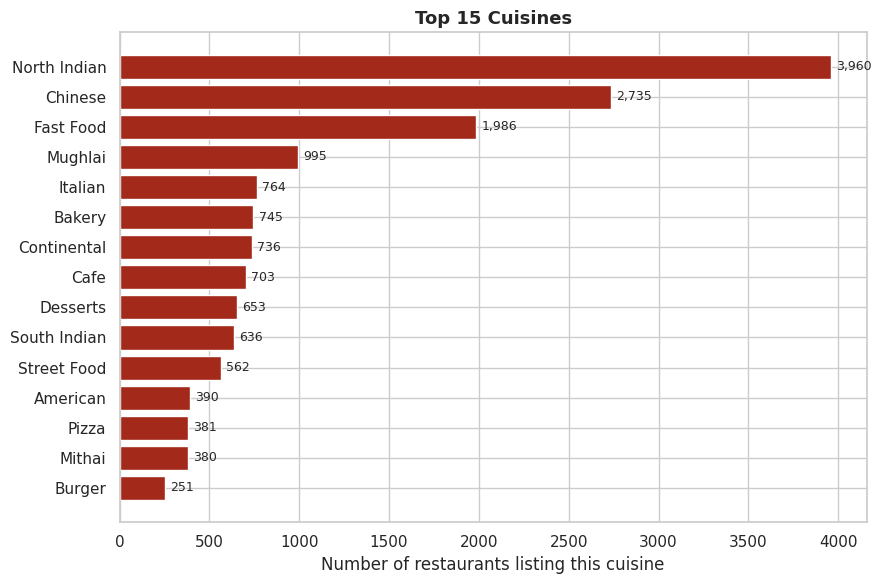

Distinct individual cuisines: 145


In [11]:
cuisine_counts = df['Cuisines'].dropna().str.split(', ').explode().value_counts()

fig, ax = plt.subplots(figsize=(9, 6))
top15 = cuisine_counts.head(15)
ax.barh(top15.index[::-1], top15.values[::-1], color=TOMATO, edgecolor='white')
for i, v in enumerate(top15.values[::-1]):
    ax.text(v + 30, i, f'{v:,}', va='center', fontsize=9)
ax.set_xlabel('Number of restaurants listing this cuisine')
ax.set_title('Top 15 Cuisines', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

print(f"Distinct individual cuisines: {cuisine_counts.shape[0]}")

<div style="
    border-left: 4px solid #3d6b4a;
    background: #eef4ef;
    padding: 14px 18px;
    margin: 6px 0 22px 0;
    border-radius: 0 6px 6px 0;
    font-family: -apple-system, Segoe UI, Roboto, sans-serif;
    font-size: 14.5px;
    line-height: 1.55;
    color: #172017;
">
<b style="color:#3d6b4a; text-transform:uppercase; font-size:11.5px; letter-spacing:1px;">Summary</b><br>
<b>North Indian (3,960)</b> and <b>Chinese (2,735)</b> lead by a wide margin, with <b>145</b> distinct cuisines in total &mdash; a pattern that fits a file where over four in five restaurants are in four Delhi-NCR cities.
</div>


<div style="
    background: linear-gradient(100deg, #3a0f0a 0%, #a3291a 46%, #e07b1f 80%, #f4d9a8 100%);
    padding: 22px 28px;
    border-radius: 10px;
    margin: 30px 0 18px 0;
    font-family: -apple-system, Segoe UI, Roboto, sans-serif;
">
<span style="
    font-family: 'Courier New', monospace;
    color: rgba(255,255,255,0.75);
    font-size: 13px;
    letter-spacing: 2px;
">SECTION 10</span>
<h2 style="color:#ffffff; margin:6px 0 4px 0; font-size:24px; font-weight:700;">Votes Are Heavily Skewed</h2>
<p style="color:rgba(255,255,255,0.92); margin:0; font-size:14.5px;">Check the shape of the Votes distribution before using it as a popularity signal.</p>
</div>


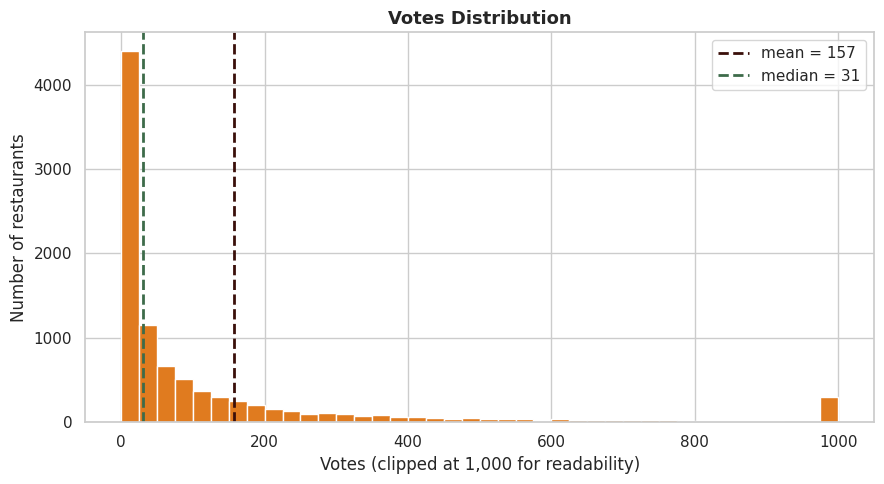

In [12]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(df['Votes'].clip(upper=1000), bins=40, color=SAFFRON, edgecolor='white')
ax.axvline(df['Votes'].mean(), color=MAROON, linestyle='--', linewidth=2, label=f"mean = {df['Votes'].mean():.0f}")
ax.axvline(df['Votes'].median(), color=BASIL, linestyle='--', linewidth=2, label=f"median = {df['Votes'].median():.0f}")
ax.set_xlabel('Votes (clipped at 1,000 for readability)')
ax.set_ylabel('Number of restaurants')
ax.set_title('Votes Distribution', fontsize=13, fontweight='bold')
ax.legend()

plt.tight_layout()
plt.show()

<div style="
    border-left: 4px solid #3d6b4a;
    background: #eef4ef;
    padding: 14px 18px;
    margin: 6px 0 22px 0;
    border-radius: 0 6px 6px 0;
    font-family: -apple-system, Segoe UI, Roboto, sans-serif;
    font-size: 14.5px;
    line-height: 1.55;
    color: #172017;
">
<b style="color:#3d6b4a; text-transform:uppercase; font-size:11.5px; letter-spacing:1px;">Summary</b><br>
Right-skewed, with the mean (157) more than <b>5&times;</b> the median (31) &mdash; a small number of well-established restaurants hold most of the accumulated votes, while most listings have barely any.
</div>


<div style="
    background: linear-gradient(100deg, #3a0f0a 0%, #a3291a 46%, #e07b1f 80%, #f4d9a8 100%);
    padding: 22px 28px;
    border-radius: 10px;
    margin: 30px 0 18px 0;
    font-family: -apple-system, Segoe UI, Roboto, sans-serif;
">
<span style="
    font-family: 'Courier New', monospace;
    color: rgba(255,255,255,0.75);
    font-size: 13px;
    letter-spacing: 2px;
">SECTION 11</span>
<h2 style="color:#ffffff; margin:6px 0 4px 0; font-size:24px; font-weight:700;">Correlation Overview</h2>
<p style="color:rgba(255,255,255,0.92); margin:0; font-size:14.5px;">Scan the core numeric variables together, using the rated, India-only subset so cost stays in one currency.</p>
</div>


Restaurants in this subset: 6513


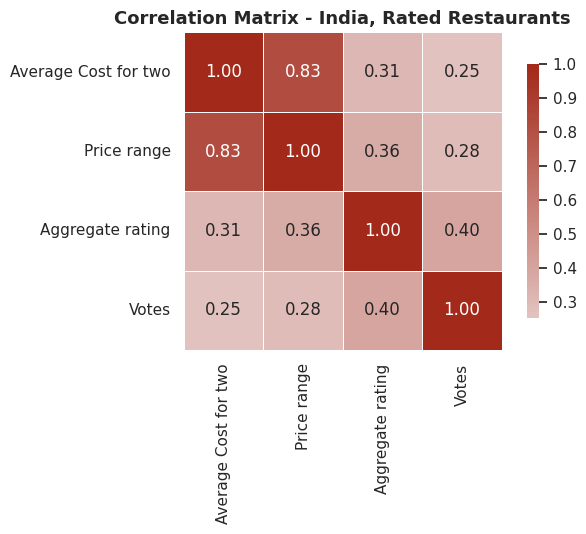

In [13]:
india_rated = rated[rated['Country Code'] == 1].copy()
numeric_cols = ['Average Cost for two', 'Price range', 'Aggregate rating', 'Votes']
corr = india_rated[numeric_cols].corr()
print(f"Restaurants in this subset: {len(india_rated)}")

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap=sns.blend_palette([BASIL, '#f7f7f7', TOMATO], as_cmap=True),
            center=0, square=True, linewidths=0.5, cbar_kws={'shrink': 0.8}, ax=ax)
ax.set_title('Correlation Matrix - India, Rated Restaurants', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

<div style="
    border-left: 4px solid #3d6b4a;
    background: #eef4ef;
    padding: 14px 18px;
    margin: 6px 0 22px 0;
    border-radius: 0 6px 6px 0;
    font-family: -apple-system, Segoe UI, Roboto, sans-serif;
    font-size: 14.5px;
    line-height: 1.55;
    color: #172017;
">
<b style="color:#3d6b4a; text-transform:uppercase; font-size:11.5px; letter-spacing:1px;">Summary</b><br>
Among the <b>6,513</b> rated Indian restaurants, <b>Votes</b> has the strongest correlation with <b>Aggregate rating</b> (<b>0.40</b>), followed by <b>Price range</b> (<b>0.36</b>) and <b>Average Cost for two</b> (<b>0.31</b>) &mdash; all modest, and none close to explaining rating on its own. <b>Price range</b> and <b>Average Cost for two</b> correlate at <b>0.83</b> with each other, as they should now that currency-mixing is excluded.
</div>


<div style="
    background: linear-gradient(100deg, #3a0f0a 0%, #a3291a 50%, #e07b1f 100%);
    padding: 28px 32px;
    border-radius: 12px;
    font-family: -apple-system, Segoe UI, Roboto, sans-serif;
    margin-top: 20px;
">
<h2 style="color:#fff; font-size:22px; margin:0 0 14px 0;">Closing Notes</h2>
<ul style="color:rgba(255,255,255,0.92); font-size:14.5px; line-height:1.8; margin:0; padding-left:20px;">
<li><b>Country Code 162's currency label is wrong</b>: 22 Metro Manila restaurants are marked Botswana Pula despite coordinates squarely in the Philippines &mdash; confirmed as an isolated mislabeling by running the same cities-and-coordinates check on all 15 country codes.</li>
<li><b>497 restaurants (5.2%) sit at placeholder (0, 0) coordinates</b>, mostly in Indian cities &mdash; any map or distance-based analysis needs to exclude them.</li>
<li><b>This is overwhelmingly a Delhi-NCR dataset</b>: India is 90.6% of all rows, and four NCR cities alone make up 82.9% of the whole file.</li>
<li><b>Unrated means fewer than 4 votes, not poorly rated</b>: all 2,148 unrated restaurants have 3 or fewer votes and every rated one has at least 4, so rating-based sections exclude them explicitly.</li>
<li><b>Never average Average Cost for two across currencies</b>: 20 Indonesian Rupiah rows (1.4% of Price-range-3 rows) make up 80.0% of that tier's raw total and push it above Price range 4. Within India alone, cost rises cleanly with price range.</li>
<li><b>Votes are heavily skewed</b> (mean 5&times; the median) and are the strongest single correlate of rating (0.40) among the rated Indian restaurants.</li>
</ul>
</div>
